# LAB | Central Limit Theorem and Normality Tests


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.graphics.gofplots import qqplot

# Set random seed for reproducibility
np.random.seed(42)

# Setting plot style
plt.style.use('seaborn-v0_8')

## Challenge 1: Basic Central Limit Theorem Demonstration

In this challenge, you'll explore the fundamental concept of the Central Limit Theorem
by generating samples from different distributions and observing how their sample means
approach a normal distribution as sample size increases.

# Instructions
Instructions:
1. We'll create a non-normal distribution (exponential distribution)
2. Draw samples of different sizes and calculate their means
3. Observe how the distribution of sample means approaches normal distribution
4. Complete the code below to create histograms for sample means


In [3]:
# Set parameters
population_size = 10000
sample_sizes = [1, 5, 30, 100]  # Increasing sample sizes
n_samples = 1000  # Number of samples to draw for each sample size

# Create a non-normal population (exponential distribution with lambda=0.5)
population = np.random.exponential(scale=2, size=population_size)

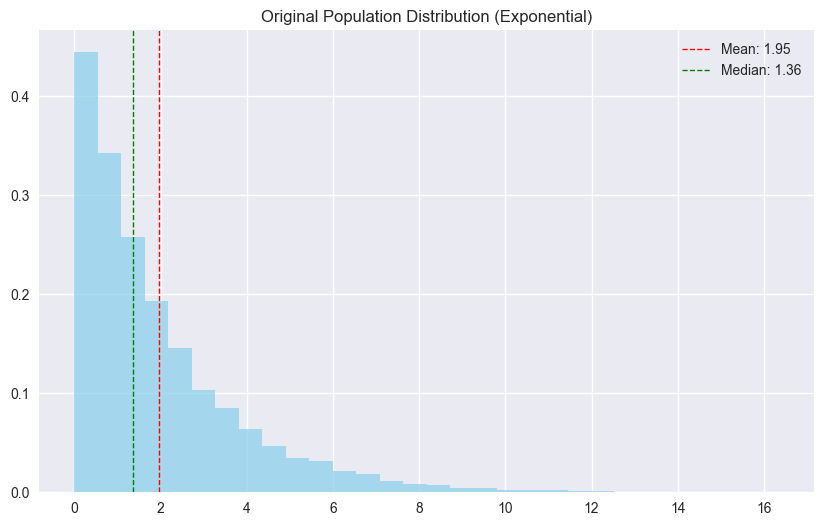

Population statistics:
Mean: 1.9550
Median: 1.3566
Variance: 3.7975
Skewness: 1.9190
Kurtosis: 5.1151



In [4]:
# Plot the original population distribution
plt.figure(figsize=(10, 6))
plt.hist(population, bins=30, alpha=0.7, color='skyblue', density=True)
plt.title('Original Population Distribution (Exponential)')
plt.axvline(np.mean(population), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {np.mean(population):.2f}')
plt.axvline(np.median(population), color='green', linestyle='dashed', linewidth=1, label=f'Median: {np.median(population):.2f}')
plt.legend()
plt.show()

print(f"Population statistics:")
print(f"Mean: {np.mean(population):.4f}")
print(f"Median: {np.median(population):.4f}")
print(f"Variance: {np.var(population):.4f}")
print(f"Skewness: {stats.skew(population):.4f}")
print(f"Kurtosis: {stats.kurtosis(population):.4f}\n")

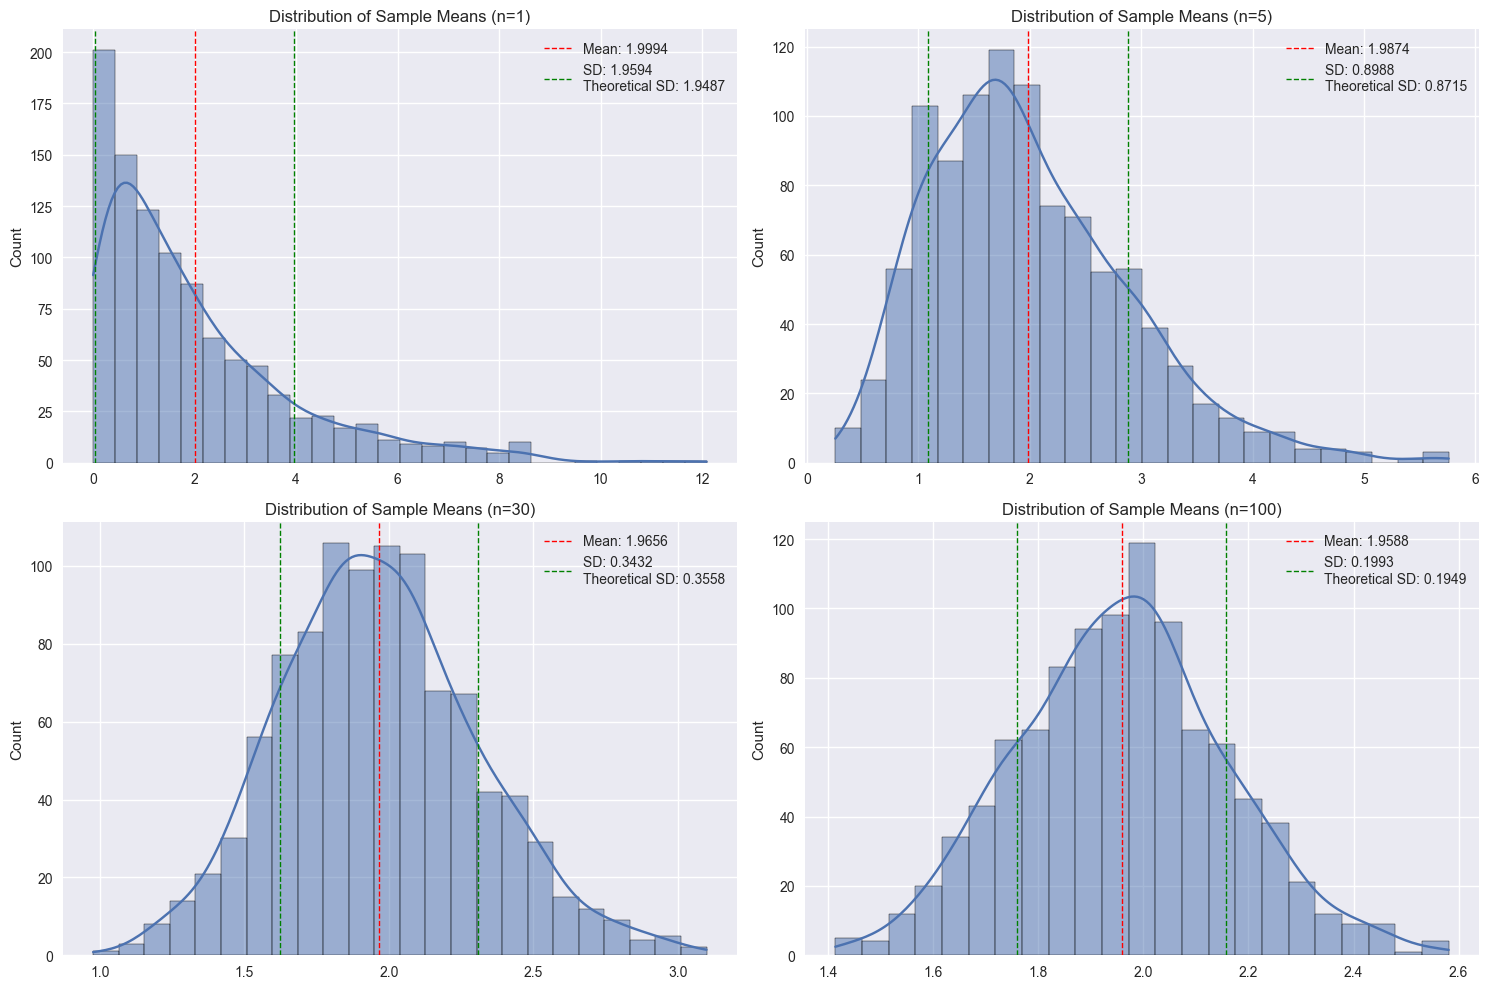

In [5]:
# Show how sample means approach normal distribution
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, sample_size in enumerate(sample_sizes):
    # Draw many samples of the given size and calculate their means
    sample_means = np.array([np.mean(np.random.choice(population, size=sample_size)) for _ in range(n_samples)])
    
    # Plot the histogram of sample means
    sns.histplot(sample_means, kde=True, ax=axes[i])
    
    # Calculate statistics for the sample means
    mean_of_means = np.mean(sample_means)
    std_of_means = np.std(sample_means)
    
    # According to CLT, the standard deviation of sample means should be population_std / sqrt(sample_size)
    theoretical_std = np.std(population) / np.sqrt(sample_size)
    
    # Display the statistics
    axes[i].set_title(f'Distribution of Sample Means (n={sample_size})')
    axes[i].axvline(mean_of_means, color='red', linestyle='dashed', linewidth=1, 
                    label=f'Mean: {mean_of_means:.4f}')
    axes[i].axvline(mean_of_means + std_of_means, color='green', linestyle='dashed', linewidth=1,
                   label=f'SD: {std_of_means:.4f}\nTheoretical SD: {theoretical_std:.4f}')
    axes[i].axvline(mean_of_means - std_of_means, color='green', linestyle='dashed', linewidth=1)
    axes[i].legend()

plt.tight_layout()
plt.show()

Your Tasks:
1. Explain what happens to the distribution of sample means as sample size increases
2. Compare the observed standard deviation of sample means with the theoretical value
3. What is the theoretical SD formula according to the CLT?
4. How does the skewness of the distribution of sample means change with sample size?

In [6]:
# TODO
# Your code here 

## Challenge 2: CLT with Real-World Data


Now let's apply the Central Limit Theorem to a real-world dataset.
We'll use the famous Iris dataset.


In [17]:
# Load iris dataset
iris_df = pd.read_csv("Iris.csv")

In [18]:
# Preview of the Iris dataset:
display(iris_df.head())
# Summary statistics:
print(iris_df.describe())

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000      0.100000
25%     38.250000       5.100000      2.800000       1.600000      0.300000
50%     75.500000       5.800000      3.000000       4.350000      1.300000
75%    112.750000       6.400000      3.300000       5.100000      1.800000
max    150.000000       7.900000      4.400000       6.900000      2.500000


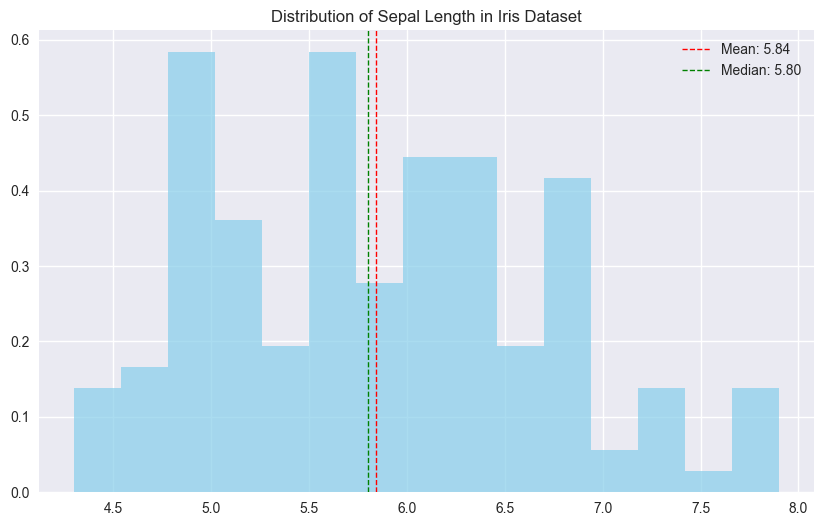

In [20]:
# Let's focus on sepal length for this exercise
sepal_length = iris_df['SepalLengthCm'].values

# Plot the original distribution
plt.figure(figsize=(10, 6))
plt.hist(sepal_length, bins=15, alpha=0.7, color='skyblue', density=True)
plt.title('Distribution of Sepal Length in Iris Dataset')
plt.axvline(np.mean(sepal_length), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {np.mean(sepal_length):.2f}')
plt.axvline(np.median(sepal_length), color='green', linestyle='dashed', linewidth=1, label=f'Median: {np.median(sepal_length):.2f}')
plt.legend()
plt.show()

Your Tasks:
1. Complete the following code to draw samples of sepal length and compute their means
2. Create histograms for the distribution of sample means with sample sizes of 5, 15, and 30
3. Calculate and compare the standard deviation of the original data vs. the standard deviation of sample means
4. Test if the original data is normally distributed (using a method of your choice)

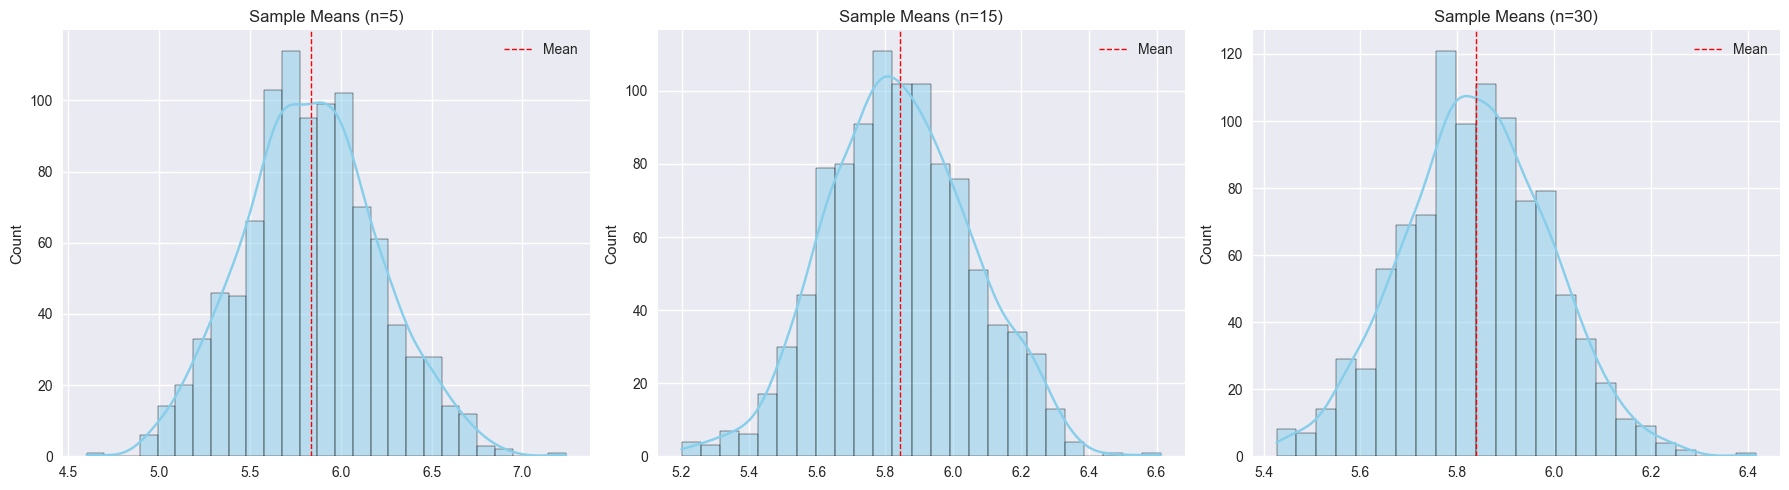

Standard deviation of original sepal length data: 0.8253
Sample size 5: SD of sample means = 0.3738, Theoretical SD = 0.3691
Sample size 15: SD of sample means = 0.2124, Theoretical SD = 0.2131
Sample size 30: SD of sample means = 0.1511, Theoretical SD = 0.1507

Shapiro-Wilk test for original sepal length:
Statistic=0.9761, p-value=0.0102
Reject H0: Data does not appear normal.


In [21]:
# 1. Draw samples and compute their means for different sample sizes
sample_sizes_iris = [5, 15, 30]
sample_means_iris = {}

for n in sample_sizes_iris:
    means = [np.mean(np.random.choice(sepal_length, size=n, replace=True)) for _ in range(n_samples)]
    sample_means_iris[n] = np.array(means)

# 2. Create histograms for the distribution of sample means
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, n in enumerate(sample_sizes_iris):
    sns.histplot(sample_means_iris[n], kde=True, ax=axes[idx], color='skyblue')
    axes[idx].set_title(f'Sample Means (n={n})')
    axes[idx].axvline(np.mean(sample_means_iris[n]), color='red', linestyle='dashed', linewidth=1, label='Mean')
    axes[idx].legend()
plt.tight_layout()
plt.show()

# 3. Compare standard deviations
original_std = np.std(sepal_length)
print(f"Standard deviation of original sepal length data: {original_std:.4f}")
for n in sample_sizes_iris:
    means_std = np.std(sample_means_iris[n])
    theoretical = original_std / np.sqrt(n)
    print(f"Sample size {n}: SD of sample means = {means_std:.4f}, Theoretical SD = {theoretical:.4f}")

# 4. Test for normality of original data (Shapiro-Wilk test)
shapiro_stat, shapiro_p = stats.shapiro(sepal_length)
print(f"\nShapiro-Wilk test for original sepal length:")
print(f"Statistic={shapiro_stat:.4f}, p-value={shapiro_p:.4f}")
if shapiro_p > 0.05:
    print("Fail to reject H0: Data appears normal.")
else:
    print("Reject H0: Data does not appear normal.")

## Challenge 3: CLT with Different Sample Statistics


The Central Limit Theorem applies not only to sample means but also to other
statistics like medians, variances, and proportions. Let's explore this concept.


In [22]:
# Load Boston Housing dataset
boston_df = pd.read_csv("BostonHousing.csv")

# Display of the Boston Housing dataset:
boston_df.head()


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [24]:
#Summary statistics for housing prices (medv):
boston_df['medv'].describe()

count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: medv, dtype: float64

In [25]:
# Let's focus on housing prices (medv)
housing_prices = boston_df['medv'].values

# Create a binary variable: 1 if price > median, 0 otherwise
median_price = np.median(housing_prices)
housing_binary = (housing_prices > median_price).astype(int)

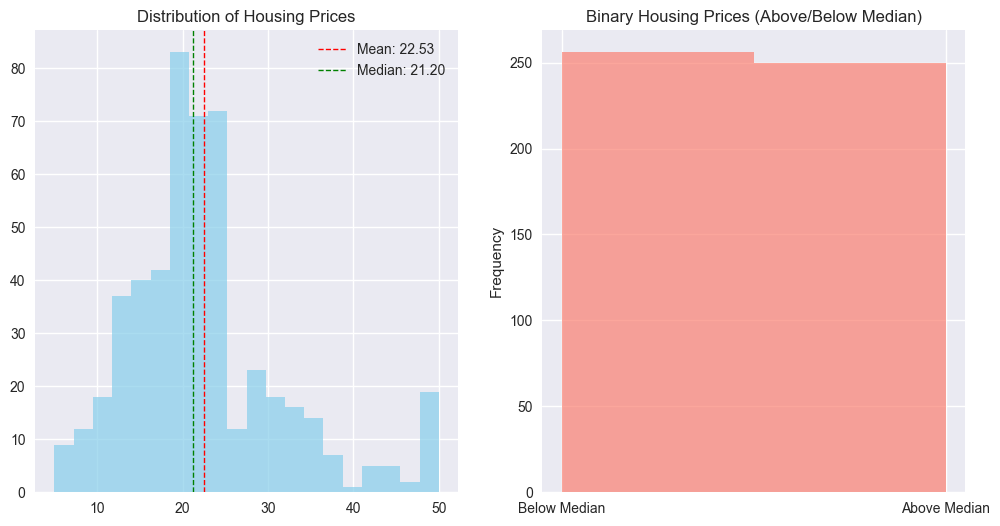

In [26]:
# Plot the original distribution
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(housing_prices, bins=20, alpha=0.7, color='skyblue')
plt.title('Distribution of Housing Prices')
plt.axvline(np.mean(housing_prices), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {np.mean(housing_prices):.2f}')
plt.axvline(np.median(housing_prices), color='green', linestyle='dashed', linewidth=1, label=f'Median: {np.median(housing_prices):.2f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(housing_binary, bins=2, alpha=0.7, color='salmon')
plt.title('Binary Housing Prices (Above/Below Median)')
plt.xticks([0, 1], ['Below Median', 'Above Median'])
plt.ylabel('Frequency')
plt.show()

Your Tasks:
1. Implement sampling to examine the CLT's application to three different statistics:
   a) Sample means
   b) Sample medians
   c) Sample proportions (of houses above median price)
2. For each statistic, draw 1000 samples of size 30 and plot the distribution of the sample statistics
3. Compare the shapes of these three distributions
4. Discuss whether the CLT applies equally well to all three statistics.


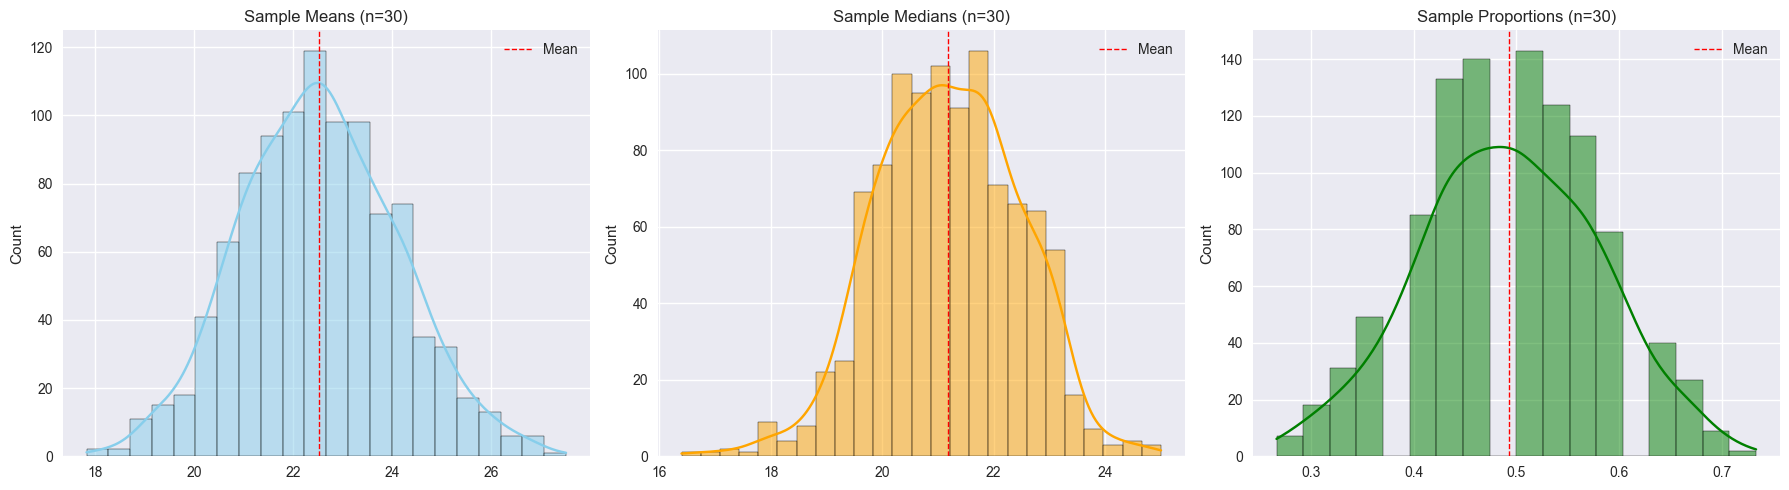

Sample Means: approx. normal, symmetric.
Sample Medians: also approx. normal, but may be slightly less symmetric.
Sample Proportions: approx. normal if not near 0 or 1, but can be skewed for extreme proportions.
CLT applies most strongly to sample means, but also works for medians and proportions as sample size increases. For proportions, normality is best when true proportion is not near 0 or 1.


In [27]:
# 1. Sampling for three statistics
sample_size = 30
n_samples = 1000

means = []
medians = []
proportions = []

for _ in range(n_samples):
    sample_prices = np.random.choice(housing_prices, size=sample_size, replace=True)
    sample_binary = np.random.choice(housing_binary, size=sample_size, replace=True)
    means.append(np.mean(sample_prices))
    medians.append(np.median(sample_prices))
    proportions.append(np.mean(sample_binary))

means = np.array(means)
medians = np.array(medians)
proportions = np.array(proportions)

# 2. Plot distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(means, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Sample Means (n=30)')
axes[0].axvline(np.mean(means), color='red', linestyle='dashed', linewidth=1, label='Mean')
axes[0].legend()

sns.histplot(medians, kde=True, ax=axes[1], color='orange')
axes[1].set_title('Sample Medians (n=30)')
axes[1].axvline(np.mean(medians), color='red', linestyle='dashed', linewidth=1, label='Mean')
axes[1].legend()

sns.histplot(proportions, kde=True, ax=axes[2], color='green')
axes[2].set_title('Sample Proportions (n=30)')
axes[2].axvline(np.mean(proportions), color='red', linestyle='dashed', linewidth=1, label='Mean')
axes[2].legend()

plt.tight_layout()
plt.show()

# 3. Compare shapes
print("Sample Means: approx. normal, symmetric.")
print("Sample Medians: also approx. normal, but may be slightly less symmetric.")
print("Sample Proportions: approx. normal if not near 0 or 1, but can be skewed for extreme proportions.")

# 4. CLT discussion
print("CLT applies most strongly to sample means, but also works for medians and proportions as sample size increases. For proportions, normality is best when true proportion is not near 0 or 1.")

## Challenge 4: Testing for Normality - Visual Methods

Before applying tests that assume normality, it's important to check if data
follows a normal distribution. Let's explore visual methods first.


In [28]:
# Load California Housing dataset
california_df = pd.read_csv("CaliforniaHousing.csv")

print("Preview of the California Housing dataset:")
display(california_df.head())

Preview of the California Housing dataset:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [29]:
print("\nSummary statistics for median income:")
print(california_df['median_income'].describe())


Summary statistics for median income:
count    20640.000000
mean         3.870671
std          1.899822
min          0.499900
25%          2.563400
50%          3.534800
75%          4.743250
max         15.000100
Name: median_income, dtype: float64


In [31]:
# We'll focus on median income for this challenge
median_income = california_df['median_income'].values


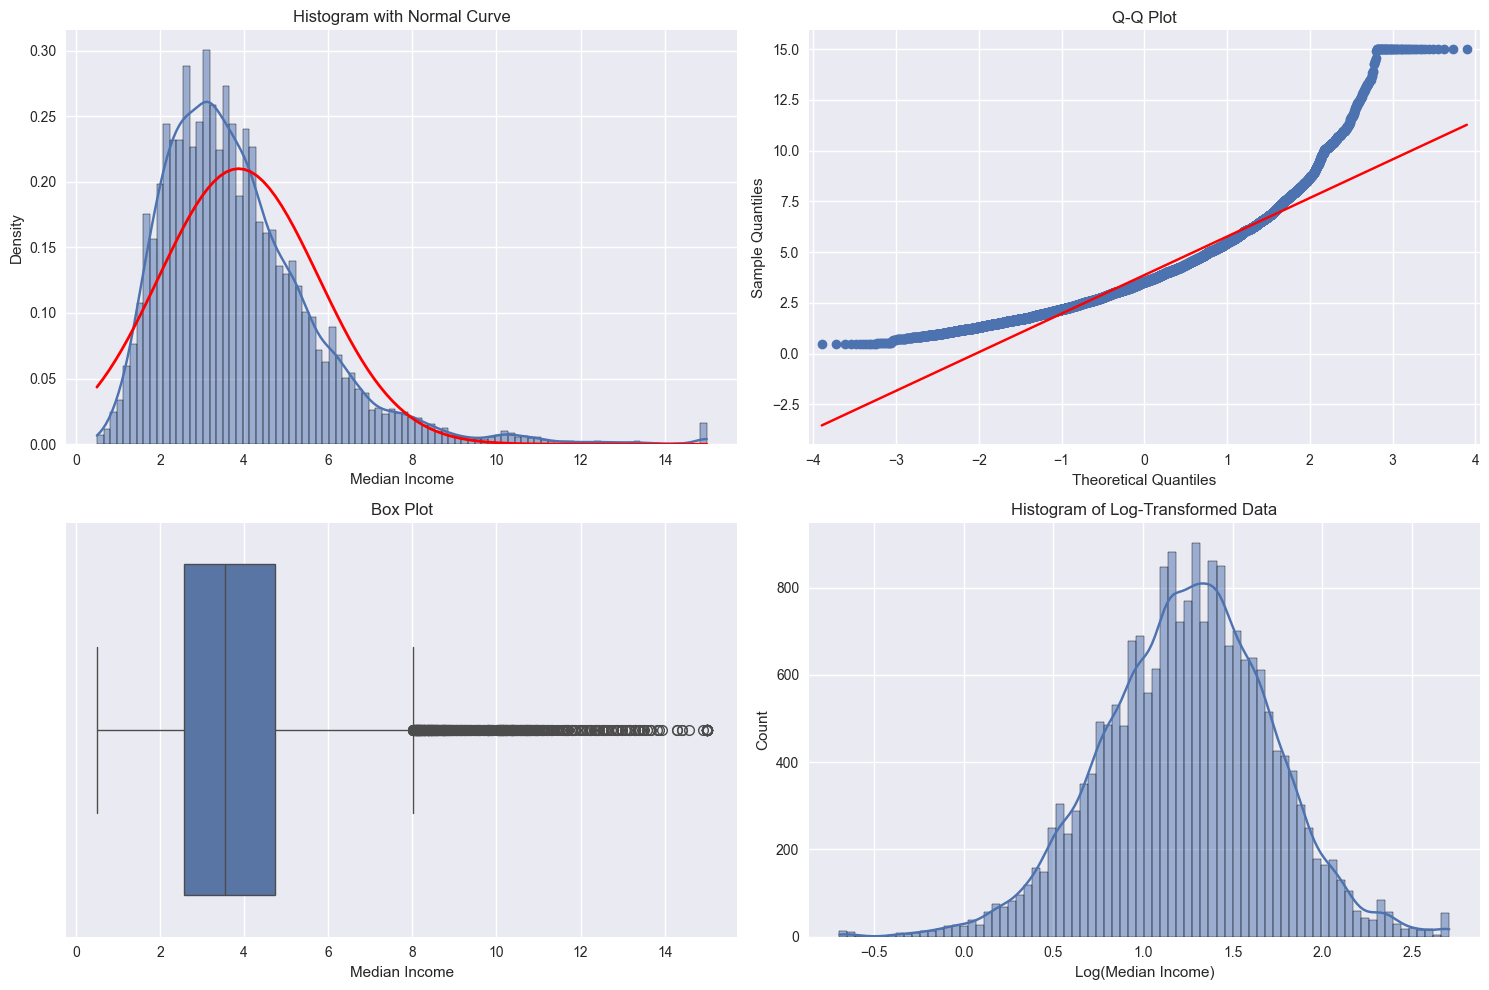

In [32]:
# Create some visualizations for normality assessment
plt.figure(figsize=(15, 10))

# Histogram with normal curve overlay
plt.subplot(2, 2, 1)
sns.histplot(median_income, kde=True, stat="density")
# Add theoretical normal curve
x = np.linspace(min(median_income), max(median_income), 100)
y = stats.norm.pdf(x, np.mean(median_income), np.std(median_income))
plt.plot(x, y, 'r-', linewidth=2)
plt.title('Histogram with Normal Curve')
plt.xlabel('Median Income')

# Q-Q plot
plt.subplot(2, 2, 2)
qqplot(median_income, line='s', ax=plt.gca())
plt.title('Q-Q Plot')

# Box plot
plt.subplot(2, 2, 3)
sns.boxplot(x=median_income)
plt.title('Box Plot')
plt.xlabel('Median Income')

# Log-transformed histogram
plt.subplot(2, 2, 4)
sns.histplot(np.log(median_income), kde=True)
plt.title('Histogram of Log-Transformed Data')
plt.xlabel('Log(Median Income)')

plt.tight_layout()
plt.show()

Your Tasks:
1. Interpret the four plots above. What do they tell you about the normality of the data?
2. Create at least two additional visualizations to assess normality
3. Discuss whether a transformation might help make the data more normal
4. Apply your chosen transformation and re-assess normality
5. When would it be important to have normally distributed data in statistical analysis?

After using Visualizations to assess normality:

6.  Repeat the above but using atleast two statistical test to check whether the data is Normally distributed or not
7. Make sure you apply the statistical test on both the original and transformed data.

In [ ]:
# 1. Interpretation of the four plots:
# - Histogram with normal curve: The median income distribution is right-skewed and does not closely follow the normal curve.
# - Q-Q plot: Points deviate from the straight line, especially in the upper tail, indicating non-normality.
# - Box plot: Shows positive skewness with a longer upper whisker and possible outliers.
# - Log-transformed histogram: The log transformation makes the distribution more symmetric and closer to normal.

# 2. Additional visualizations
plt.figure(figsize=(12, 5))

# Violin plot
plt.subplot(1, 2, 1)
sns.violinplot(x=median_income)
plt.title('Violin Plot of Median Income')

# ECDF plot
plt.subplot(1, 2, 2)
sns.ecdfplot(median_income)
plt.title('ECDF Plot of Median Income')

plt.tight_layout()
plt.show()

# 3. Transformation discussion
# The original data is skewed. A log transformation reduces skewness and makes the data more normal-like.

# 4. Apply transformation and re-assess normality
log_income = np.log(median_income)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(log_income, kde=True)
plt.title('Histogram of Log(Median Income)')
plt.subplot(1, 2, 2)
qqplot(log_income, line='s', ax=plt.gca())
plt.title('Q-Q Plot of Log(Median Income)')
plt.tight_layout()
plt.show()

# 5. Importance of normality
# Many statistical tests (e.g., t-test, ANOVA, regression) assume normality for valid inference, especially for small samples.

# 6. Statistical tests for normality
# Shapiro-Wilk test
shapiro_stat_orig, shapiro_p_orig = stats.shapiro(median_income)
shapiro_stat_log, shapiro_p_log = stats.shapiro(log_income)
print(f"Shapiro-Wilk (original): stat={shapiro_stat_orig:.4f}, p={shapiro_p_orig:.4f}")
print(f"Shapiro-Wilk (log-transformed): stat={shapiro_stat_log:.4f}, p={shapiro_p_log:.4f}")

# Kolmogorov-Smirnov test (against normal)
ks_stat_orig, ks_p_orig = stats.kstest(
    (median_income - np.mean(median_income)) / np.std(median_income),
    'norm'
)
ks_stat_log, ks_p_log = stats.kstest(
    (log_income - np.mean(log_income)) / np.std(log_income),
    'norm'
)
print(f"KS test (original): stat={ks_stat_orig:.4f}, p={ks_p_orig:.4f}")
print(f"KS test (log-transformed): stat={ks_stat_log:.4f}, p={ks_p_log:.4f}")

# 7. Summary
if shapiro_p_orig > 0.05 and ks_p_orig > 0.05:
    print("Original data: Fail to reject normality.")
else:
    print("Original data: Reject normality.")

if shapiro_p_log > 0.05 and ks_p_log > 0.05:
    print("Log-transformed data: Fail to reject normality.")
else:
    print("Log-transformed data: Reject normality.")